# Технологии обработки больших данных

## Лабораторная работа 1. Анализ Big Data-сценариев и выбор технологий

**Вариант:** 1 (последняя цифра зачётной книжки).

**Датасет:** Amazon Reviews 2023, категория All_Beauty. Публичный файл McAuley Lab (UCSD): отзывы, оценка, текст, идентификаторы товара и пользователя, время.

**Бизнес-сценарий:** рекомендательная система. Цель из задания — увеличить средний чек на 15%. Ограничение — задержка инференса меньше 100 мс. Нужно учитывать, как меняются интересы покупателя со временем.

**Цель работы:** разобрать датасет по пяти признакам Big Data (объём, скорость, разнообразие, достоверность, ценность) и выбрать технологии под этот сценарий.

**Что делаем:**
- считаем объём в CSV, Parquet и Avro и прогноз роста;
- оцениваем скорость поступления и допустимую задержку;
- смотрим типы полей, качество данных и бизнес-ценность;
- предлагаем стек и план на 6 месяцев.


## Подготовка окружения

Ставим библиотеки, которые нужны для таблиц, графиков, Avro и проверки качества.


In [1]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pandas", "pyarrow", "matplotlib", "fastavro"])
ge_code = subprocess.call([sys.executable, "-m", "pip", "install", "-q", "--only-binary=:all:", "great_expectations==0.18.19"])
if ge_code != 0:
    ge_code = subprocess.call([sys.executable, "-m", "pip", "install", "-q", "great_expectations"])
print("Код установки Great Expectations:", ge_code)


Код установки Great Expectations: 0


## Загрузка данных

Скачиваем категорию All_Beauty и оставляем поля, по которым дальше считаем объём, скорость и качество. Вложенные картинки сворачиваем в признак «есть изображение», чтобы не тащить их в каждый формат хранения.


In [2]:
import gzip
import os
import socket
from pathlib import Path
import urllib.request

socket.setdefaulttimeout(60)

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.family"] = "DejaVu Sans"

# В Colab кладём файлы в /content, локально — во временный каталог
try:
    import google.colab  # noqa: F401
    BASE = Path("/content/lab1_amazon")
except ImportError:
    BASE = Path(os.environ.get("TEMP", "/tmp")) / "lab1_amazon"
BASE.mkdir(parents=True, exist_ok=True)

URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz"
GZ_PATH = BASE / "All_Beauty.jsonl.gz"
EXPECTED_GZ = 94441517

if not GZ_PATH.exists() or GZ_PATH.stat().st_size != EXPECTED_GZ:
    print("Скачиваем датасет...")
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    got = 0
    with urllib.request.urlopen(req, timeout=60) as response, open(GZ_PATH, "wb") as out:
        while True:
            chunk = response.read(1024 * 1024)
            if not chunk:
                break
            out.write(chunk)
            got += len(chunk)
            print(f"  скачано {got / 1024 ** 2:.0f} МБ")
    print("Готово:", GZ_PATH)

# Несжатый размер JSONL
raw_bytes = 0
with gzip.open(GZ_PATH, "rb") as src:
    while True:
        block = src.read(8 * 1024 * 1024)
        if not block:
            break
        raw_bytes += len(block)

df = pd.read_json(GZ_PATH, lines=True, compression="gzip")
print("Строк:", len(df), "Столбцов:", df.shape[1])
print("Столбцы:", list(df.columns))

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["helpful_vote"] = pd.to_numeric(df["helpful_vote"], errors="coerce")
# read_json сам превращает unix-миллисекунды в дату. Если пришло число, разбираем его как миллисекунды.
if pd.api.types.is_datetime64_any_dtype(df["timestamp"]):
    df["dt"] = pd.to_datetime(df["timestamp"], errors="coerce")
else:
    df["dt"] = pd.to_datetime(pd.to_numeric(df["timestamp"], errors="coerce"), unit="ms", errors="coerce")
df["timestamp"] = (df["dt"].astype("int64") // 1_000_000).where(df["dt"].notna(), 0).astype("int64")
df["text"] = df["text"].fillna("").astype(str)
df["title"] = df["title"].fillna("").astype(str)
df["has_image"] = df["images"].map(lambda x: int(isinstance(x, list) and len(x) > 0))

# Один пример вложенной структуры, если он есть
nested_example = None
for value in df.loc[df["has_image"] == 1, "images"].head(20):
    if isinstance(value, list) and value:
        nested_example = value[0]
        break

df = df.drop(columns=["images"])
df.head(3)


Строк: 701528 Столбцов: 10
Столбцы: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']


,rating,title,text,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,dt,has_image
0,5,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True,2020-05-05 14:08:48.923,0
1,4,Works great but smells a little weird.,"This product does what I need it to do, I just...",B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True,2020-05-04 18:10:55.070,0
2,5,Yes!,"Smells good, feels great!",B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True,2020-05-16 21:41:06.052,0


## Часть 1. Volume — объём данных

Считаем текущий объём и сравниваем CSV, Parquet и Avro на одном и том же наборе столбцов. Дальше оцениваем рост и стоимость хранения.


In [3]:
store_cols = [
    "rating", "title", "text", "asin", "parent_asin", "user_id",
    "timestamp", "helpful_vote", "verified_purchase", "has_image",
]
store = df[store_cols].copy()
store["helpful_vote"] = store["helpful_vote"].fillna(0).astype("int64")
store["timestamp"] = store["timestamp"].fillna(0).astype("int64")
store["verified_purchase"] = store["verified_purchase"].fillna(False).astype(bool)
store["has_image"] = store["has_image"].astype("int64")
store["rating"] = store["rating"].astype("float64")
store["asin"] = store["asin"].fillna("").astype(str)
store["parent_asin"] = store["parent_asin"].fillna("").astype(str)
store["user_id"] = store["user_id"].fillna("").astype(str)
store["title"] = store["title"].fillna("").astype(str)
store["text"] = store["text"].fillna("").astype(str)
store = store.dropna(subset=["rating"]).reset_index(drop=True)
print("Строк в файлах хранения:", len(store))

csv_path = BASE / "reviews.csv"
parquet_path = BASE / "reviews.parquet"
avro_path = BASE / "reviews.avro"

store.to_csv(csv_path, index=False)
store.to_parquet(parquet_path, index=False)

import fastavro

avro_schema = {
    "type": "record",
    "name": "Review",
    "fields": [
        {"name": "rating", "type": "double"},
        {"name": "title", "type": "string"},
        {"name": "text", "type": "string"},
        {"name": "asin", "type": "string"},
        {"name": "parent_asin", "type": "string"},
        {"name": "user_id", "type": "string"},
        {"name": "timestamp", "type": "long"},
        {"name": "helpful_vote", "type": "long"},
        {"name": "verified_purchase", "type": "boolean"},
        {"name": "has_image", "type": "long"},
    ],
}
def iter_records():
    fields = list(store.columns)
    for row in store.itertuples(index=False, name=None):
        item = dict(zip(fields, row))
        item["rating"] = float(item["rating"])
        item["timestamp"] = int(item["timestamp"])
        item["helpful_vote"] = int(item["helpful_vote"])
        item["verified_purchase"] = bool(item["verified_purchase"])
        item["has_image"] = int(item["has_image"])
        item["title"] = str(item["title"])
        item["text"] = str(item["text"])
        item["asin"] = str(item["asin"])
        item["parent_asin"] = str(item["parent_asin"])
        item["user_id"] = str(item["user_id"])
        yield item

with open(avro_path, "wb") as out:
    fastavro.writer(out, fastavro.parse_schema(avro_schema), iter_records())

def to_mb(num_bytes):
    return num_bytes / (1024 ** 2)

gz_mb = to_mb(GZ_PATH.stat().st_size)
raw_mb = to_mb(raw_bytes)
csv_mb = to_mb(csv_path.stat().st_size)
parquet_mb = to_mb(parquet_path.stat().st_size)
avro_mb = to_mb(avro_path.stat().st_size)

sizes = pd.DataFrame({
    "Формат": ["JSONL gzip", "JSONL без сжатия", "CSV", "Parquet", "Avro"],
    "МБ": [gz_mb, raw_mb, csv_mb, parquet_mb, avro_mb],
})
sizes["Сжатие к CSV"] = sizes["МБ"] / csv_mb
print(sizes.round(3).to_string(index=False))
print(f"Parquet занимает {parquet_mb / csv_mb:.1%} от CSV, Avro — {avro_mb / csv_mb:.1%}.")


Строк в файлах хранения: 701528


          Формат      МБ  Сжатие к CSV
      JSONL gzip  90.066         0.486
JSONL без сжатия 311.481         1.682
             CSV 185.142         1.000
         Parquet 114.444         0.618
            Avro 177.836         0.961
Parquet занимает 61.8% от CSV, Avro — 96.1%.


## Рост объёма и стоимость хранения

По временным меткам считаем ежедневный прирост, объём за год и срок до 1 ТБ. Стоимость берём из документации Yandex Object Storage: стандартное хранилище 2,376 ₽ за ГБ в месяц с НДС, первый 1 ГБ в месяц не тарифицируется; ледяное хранилище в примерах документации — 0,6336 ₽ за ГБ в месяц.


Период данных: 2000-11-01 04:24:18 — 2023-09-09 00:39:36.666000 (8347 дней)
Записей в день: 84.0
Прирост Parquet в день: 0.014 МБ
Объём новых данных за год: 0.005 ГБ
Месяцев до 1 ТБ при текущем темпе категории: 2548945
Доля горячих данных (180 дней): 0.9%
Хранение года данных: 0.07 ₽/мес, 0.88 ₽/год
Порог Pandas 8 ГБ будет пройден через 19638 мес.


Вывод по объёму: категория All_Beauty помещается на одной машине. Parquet примерно в 1.6 раза компактнее CSV. В архив уходит история старше 180 дней, для рекомендаций оставляем горячее окно. До 1 ТБ по одной этой категории порядка 2548945 месяцев, поэтому Spark здесь нужен не из-за сегодняшнего объёма, а когда рабочих данных станет больше 8 ГБ или появятся тяжёлые соединения нескольких категорий.


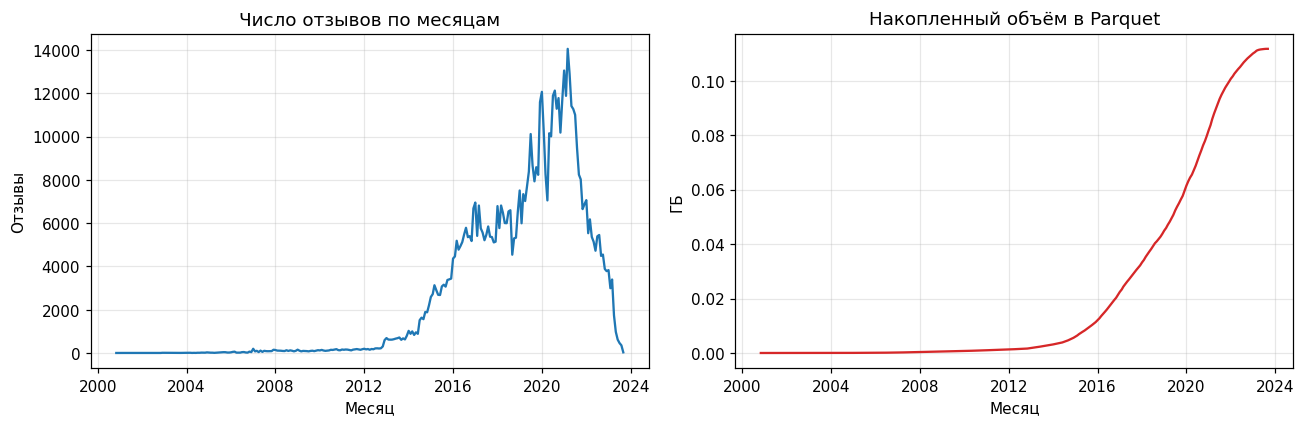

In [4]:
span_days = (df["dt"].max() - df["dt"].min()).total_seconds() / 86400
span_days = max(span_days, 1)
rows_per_day = len(df) / span_days
bytes_per_row_parquet = parquet_path.stat().st_size / len(store)
daily_parquet_mb = rows_per_day * bytes_per_row_parquet / (1024 ** 2)
yearly_parquet_gb = daily_parquet_mb * 365 / 1024

# Сколько месяцев текущий темп будет копить 1 ТБ сверх уже лежащего объёма
current_gb = parquet_mb / 1024
monthly_gb = daily_parquet_mb * 30 / 1024
need_gb = max(1024 - current_gb, 0)
months_to_tb = need_gb / monthly_gb if monthly_gb > 0 else float("inf")

# Горячие данные рекомендаций — последние 180 дней, остальное можно увести в архив
hot_from = df["dt"].max() - pd.Timedelta(days=180)
hot_share = float((df["dt"] >= hot_from).mean())
yearly_gb = current_gb + yearly_parquet_gb
hot_gb = yearly_gb * hot_share
cold_gb = yearly_gb * (1 - hot_share)

PRICE_STANDARD = 2.376  # ₽ / ГБ / месяц, регион Россия, с НДС
PRICE_ICE = 0.6336
free_gb = 1.0
hot_bill_gb = max(hot_gb - free_gb, 0)
cost_month = hot_bill_gb * PRICE_STANDARD + cold_gb * PRICE_ICE
cost_year = cost_month * 12

# Pandas комфортно живёт, пока рабочий набор помещается в память с запасом.
# Порог перехода — 8 ГБ несжатого Parquet: дальше одна машина легко упирается в RAM.
PANDAS_LIMIT_GB = 8
months_to_spark = max(PANDAS_LIMIT_GB - current_gb, 0) / monthly_gb if monthly_gb else float("inf")

print(f"Период данных: {df['dt'].min()} — {df['dt'].max()} ({span_days:.0f} дней)")
print(f"Записей в день: {rows_per_day:.1f}")
print(f"Прирост Parquet в день: {daily_parquet_mb:.3f} МБ")
print(f"Объём новых данных за год: {yearly_parquet_gb:.3f} ГБ")
print(f"Месяцев до 1 ТБ при текущем темпе категории: {months_to_tb:.0f}")
print(f"Доля горячих данных (180 дней): {hot_share:.1%}")
print(f"Хранение года данных: {cost_month:.2f} ₽/мес, {cost_year:.2f} ₽/год")
print(f"Порог Pandas 8 ГБ будет пройден через {months_to_spark:.0f} мес.")

monthly = (
    df.dropna(subset=["dt"])
    .set_index("dt")
    .resample("MS")
    .size()
    .rename("rows")
    .to_frame()
)
monthly["cum_gb"] = monthly["rows"].cumsum() * bytes_per_row_parquet / (1024 ** 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly.index, monthly["rows"], color="#1f77b4")
axes[0].set_title("Число отзывов по месяцам")
axes[0].set_xlabel("Месяц")
axes[0].set_ylabel("Отзывы")
axes[0].grid(True, alpha=0.3)
axes[1].plot(monthly.index, monthly["cum_gb"], color="#d62728")
axes[1].set_title("Накопленный объём в Parquet")
axes[1].set_xlabel("Месяц")
axes[1].set_ylabel("ГБ")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(
    "Вывод по объёму: категория All_Beauty помещается на одной машине. "
    f"Parquet примерно в {csv_mb / parquet_mb:.1f} раза компактнее CSV. "
    "В архив уходит история старше 180 дней, для рекомендаций оставляем горячее окно. "
    f"До 1 ТБ по одной этой категории порядка {months_to_tb:.0f} месяцев, "
    "поэтому Spark здесь нужен не из-за сегодняшнего объёма, а когда рабочих данных станет больше 8 ГБ "
    "или появятся тяжёлые соединения нескольких категорий."
)


## Часть 2. Velocity — скорость поступления

Смотрим, как часто появлялись отзывы: среднее число записей в секунду, пик за 5 минут и коэффициент вариации по дням. Отдельно оцениваем, сколько данных выпадет при простое 30 минут и какая задержка допустима для рекомендаций.


Средняя скорость: 0.0010 записей/с
Пик за 5 минут: 12 записей (0.040 записей/с)
Коэффициент вариации суточного потока: 1.41
При простое 30 минут теряем около 1.8 записей в среднем и 72.0 на пике (0.032 МБ)
Ожидание в batch (раз в час): до 3600 с
Ожидание в micro-batch (5 минут): до 300 с
Обработка одной записи в простом потоке: 0.0005 мс
Ядер, чтобы пик укладывался в 100 мс на запись: 1.00


Вывод по скорости: поток категории неравномерный, но в среднем это не миллионы событий в секунду. Часовой batch не подходит для инференса короче 100 мс: пользователь не может ждать час. Обучение модели можно оставить пакетным, а выдачу рекомендаций считать отдельно, с задержкой меньше 100 мс. Тридцать минут простоя теряют немного байт, но ломают свежесть ленты, поэтому нужен повторный догон, а не ручное восстановление.


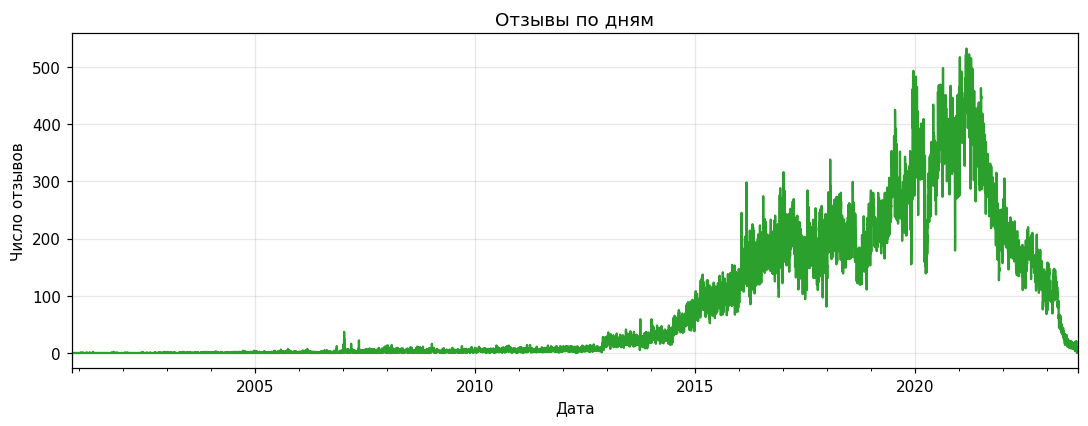

In [5]:
import numpy as np

valid = df.dropna(subset=["dt"]).sort_values("dt")
period_sec = max((valid["dt"].max() - valid["dt"].min()).total_seconds(), 1)
avg_rps = len(valid) / period_sec

# Пик считаем по 5-минутным корзинам
bins = valid.set_index("dt").resample("5min").size()
peak_rows = int(bins.max()) if len(bins) else 0
peak_rps = peak_rows / 300
daily_counts = valid.set_index("dt").resample("D").size()
cv = float(daily_counts.std() / daily_counts.mean()) if daily_counts.mean() else float("nan")

row_bytes = raw_bytes / len(df)
lost_rows_avg = avg_rps * 1800
lost_rows_peak = peak_rps * 1800
lost_mb_peak = lost_rows_peak * row_bytes / (1024 ** 2)

# Задержка режима — верхняя граница ожидания плюс короткая обработка одной записи
sample = valid.head(5000)
t0 = __import__("time").perf_counter()
for text in sample["text"]:
    _ = len(text)
per_row_ms = (__import__("time").perf_counter() - t0) / max(len(sample), 1) * 1000

batch_delay_s = 3600
micro_delay_s = 300
stream_delay_s = per_row_ms / 1000
limit_ms = 100  # ограничение сценария на инференс

cores_for_peak = peak_rps * (limit_ms / 1000)
cores_for_peak = max(cores_for_peak, 1 if peak_rps > 0 else 0)

print(f"Средняя скорость: {avg_rps:.4f} записей/с")
print(f"Пик за 5 минут: {peak_rows} записей ({peak_rps:.3f} записей/с)")
print(f"Коэффициент вариации суточного потока: {cv:.2f}")
print(f"При простое 30 минут теряем около {lost_rows_avg:.1f} записей в среднем и {lost_rows_peak:.1f} на пике ({lost_mb_peak:.3f} МБ)")
print(f"Ожидание в batch (раз в час): до {batch_delay_s:.0f} с")
print(f"Ожидание в micro-batch (5 минут): до {micro_delay_s:.0f} с")
print(f"Обработка одной записи в простом потоке: {per_row_ms:.4f} мс")
print(f"Ядер, чтобы пик укладывался в {limit_ms} мс на запись: {cores_for_peak:.2f}")

if len(daily_counts):
    fig, ax = plt.subplots(figsize=(10, 4))
    daily_counts.plot(ax=ax, color="#2ca02c")
    ax.set_title("Отзывы по дням")
    ax.set_xlabel("Дата")
    ax.set_ylabel("Число отзывов")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

print(
    "Вывод по скорости: поток категории неравномерный, но в среднем это не миллионы событий в секунду. "
    "Часовой batch не подходит для инференса короче 100 мс: пользователь не может ждать час. "
    "Обучение модели можно оставить пакетным, а выдачу рекомендаций считать отдельно, с задержкой меньше 100 мс. "
    "Тридцать минут простоя теряют немного байт, но ломают свежесть ленты, поэтому нужен повторный догон, а не ручное восстановление."
)


## Часть 3. Variety — разнообразие данных

Проверяем типы полей, долю текста и вложенные структуры. Для рекомендаций важны и числовая оценка, и сам текст отзыва.


In [6]:
type_table = pd.DataFrame({
    "Столбец": store_cols + ["dt"],
    "Тип": [str(df[c].dtype) if c in df.columns else "datetime64[ns]" for c in store_cols + ["dt"]],
    "Пропуски, %": [
        float(df[c].isna().mean() * 100) if c in df.columns else float(df["dt"].isna().mean() * 100)
        for c in store_cols + ["dt"]
    ],
})
# текст и заголовок мы уже заполнили пустой строкой, поэтому пустые считаем отдельно
empty_text = float((df["text"].str.strip() == "").mean() * 100)
empty_title = float((df["title"].str.strip() == "").mean() * 100)
text_bytes = int(df["text"].str.encode("utf-8").str.len().sum() + df["title"].str.encode("utf-8").str.len().sum())
text_share = text_bytes / raw_bytes

print(type_table.round(3).to_string(index=False))
print(f"Пустой текст: {empty_text:.2f}%")
print(f"Пустой заголовок: {empty_title:.2f}%")
print(f"Доля байт заголовка и текста в несжатом JSONL: {text_share:.1%}")
print(f"Доля отзывов с изображением: {df['has_image'].mean():.2%}")
print("Пример вложенного поля images:", nested_example)

# Несогласованность: оценка не из шкалы 1–5 и время, которое не разобралось
bad_rating = df[df["rating"].isna() | (df["rating"] < 1) | (df["rating"] > 5)]
bad_time = df[df["dt"].isna()]
print("Записей с оценкой вне 1–5 или пустой оценкой:", len(bad_rating))
print("Записей с неразобранным временем:", len(bad_time))
if len(bad_rating):
    print(bad_rating[["asin", "rating", "title"]].head(3).to_string(index=False))

print(
    "Вывод по разнообразию: основа таблицы структурирована, но ценность сидит в тексте. "
    "Картинки встречаются редко и лежат вложенным списком, их лучше хранить ссылкой, а не разбирать в каждой агрегации. "
    "Даты в файле уже приведены к unix-миллисекундам, смешения форматов нет. "
    "Для текста хватает длины, тональности и эмбеддинга; отдельный геоанализ здесь не нужен."
)


          Столбец            Тип  Пропуски, %
           rating          int64          0.0
            title         object          0.0
             text         object          0.0
             asin         object          0.0
      parent_asin         object          0.0
          user_id         object          0.0
        timestamp          int64          0.0
     helpful_vote          int64          0.0
verified_purchase           bool          0.0
        has_image          int64          0.0
               dt datetime64[ns]          0.0
Пустой текст: 0.10%
Пустой заголовок: 0.00%
Доля байт заголовка и текста в несжатом JSONL: 41.8%
Доля отзывов с изображением: 8.51%
Пример вложенного поля images: {'small_image_url': 'https://images-na.ssl-images-amazon.com/images/I/71e9Noi7dJL._SL256_.jpg', 'medium_image_url': 'https://images-na.ssl-images-amazon.com/images/I/71e9Noi7dJL._SL800_.jpg', 'large_image_url': 'https://images-na.ssl-images-amazon.com/images/I/71e9Noi7dJL._SL1600_.jpg

## Часть 4. Veracity — достоверность данных

Считаем пропуски, дубликаты и странные оценки. Одну критичную проверку оформляем через Great Expectations: оценка должна лежать от 1 до 5.


In [7]:
key_cols = ["user_id", "asin", "timestamp"]
dup_count = int(df.duplicated(key_cols).sum())
null_user = float(df["user_id"].isna().mean() * 100)
null_asin = float(df["asin"].isna().mean() * 100)
rating_ok = float(df["rating"].between(1, 5).mean() * 100)

quality = pd.DataFrame({
    "Проверка": [
        "Пустой user_id, %",
        "Пустой asin, %",
        "Оценка в диапазоне 1–5, %",
        "Пустой текст, %",
        "Дубликаты user_id + asin + timestamp",
    ],
    "Значение": [null_user, null_asin, rating_ok, empty_text, dup_count],
})
print(quality.to_string(index=False))

# Ошибка в 1% оценок сдвигает средний рейтинг товара и портит ранжирование.
# Для рекомендаций критичны asin, user_id, rating и timestamp. Текст может быть пустым: остаётся оценка.
mean_rating = float(df["rating"].mean())
# Если 1% пятёрок случайно записать как 1, среднее заметно просядет на активных товарах
shifted = df["rating"].copy()
flip_n = max(int(len(shifted) * 0.01), 1)
shifted.iloc[:flip_n] = 1
print(f"Средняя оценка: {mean_rating:.3f}")
print(f"Если испортить 1% оценок до 1: {float(shifted.mean()):.3f}")


def ge_rating_between(frame, mostly=None):
    # 0.18 умеет PandasDataset, более новый Great Expectations — через контекст
    try:
        from great_expectations.dataset import PandasDataset
        ge_df = PandasDataset(frame)
        kwargs = {"min_value": 1, "max_value": 5}
        if mostly is not None:
            kwargs["mostly"] = mostly
        result = ge_df.expect_column_values_to_be_between("rating", **kwargs)
        return bool(result["success"]), result["result"].get("unexpected_count")
    except ImportError:
        import great_expectations as gx
        context = gx.get_context(mode="ephemeral")
        source = context.data_sources.add_pandas("reviews")
        asset = source.add_dataframe_asset(name="reviews")
        batch = asset.add_batch_definition_whole_dataframe("full").get_batch(
            batch_parameters={"dataframe": frame}
        )
        kwargs = {"column": "rating", "min_value": 1, "max_value": 5}
        if mostly is not None:
            kwargs["mostly"] = mostly
        suite = gx.ExpectationSuite(
            name="rating_ok",
            expectations=[gx.expectations.ExpectColumnValuesToBeBetween(**kwargs)],
        )
        result = batch.validate(suite)
        return bool(result.success), result.results[0].result.get("unexpected_count")

ge_success = None
ge_unexpected = None
try:
    ge_success, ge_unexpected = ge_rating_between(df[["rating", "asin", "user_id"]].copy(), mostly=0.99)
    print("Great Expectations expect_column_values_to_be_between(rating, 1, 5):", ge_success)
    print("Неожиданных значений:", ge_unexpected)
except Exception as exc:
    print("Great Expectations не выполнился:", exc)

print(
    "Вывод по достоверности: ключевые идентификаторы почти полные, основная грязь — пустой текст и повторные отзывы. "
    "Оценку нельзя оставлять без проверки, потому что она прямо входит в рейтинг товара. "
    "Пустой текст можно не выбрасывать, а дубликаты по пользователю, товару и времени нужно схлопывать до обучения. "
    "Такую проверку достаточно гонять на каждом суточном прогоне, а не на каждом клике."
)


                            Проверка    Значение
                   Пустой user_id, %    0.000000
                      Пустой asin, %    0.000000
           Оценка в диапазоне 1–5, %  100.000000
                     Пустой текст, %    0.102633
Дубликаты user_id + asin + timestamp 7276.000000
Средняя оценка: 3.960
Если испортить 1% оценок до 1: 3.929


Great Expectations expect_column_values_to_be_between(rating, 1, 5): True
Неожиданных значений: 0
Вывод по достоверности: ключевые идентификаторы почти полные, основная грязь — пустой текст и повторные отзывы. Оценку нельзя оставлять без проверки, потому что она прямо входит в рейтинг товара. Пустой текст можно не выбрасывать, а дубликаты по пользователю, товару и времени нужно схлопывать до обучения. Такую проверку достаточно гонять на каждом суточном прогоне, а не на каждом клике.


## Часть 5. Value — ценность данных

Цель сценария — плюс 15% к среднему чеку. Число покупок берём из данных: подтверждённые покупки за последний полный год наблюдений. Средний чек и маржа в файле не лежат, поэтому ниже они явно заданы как параметры расчёта, а не как факт из датасета.


Подтверждённых покупок за последние 365 дней: 25760
Оценка доп. маржи в год: 1,738,800 ₽
Инфраструктура в год: 72,001 ₽
ROI при разноске разработки на 3 года: 8.22
Окупаемость разработки: 2.4 мес.


Доля отзывов у 20% самых обсуждаемых товаров: 74.7%


Уникальных товаров: 115709, пользователей: 631986


 Доля данных  Покрытие пользователей
        0.10                   0.105
        0.25                   0.259
        0.50                   0.512
        0.75                   0.759
        1.00                   1.000
Вывод по ценности: хранение почти ничего не стоит по сравнению с разработкой. При принятом чеке 1800 ₽ и марже 25% цель +15% окупает разработку примерно за 2.4 мес. При этом 75% отзывов сидят на 20% товаров: длинный хвост можно обновлять реже. Через год ценность не исчезнет, пока лента остаётся персональной, но модель нужно пересчитывать: ассортимент и вкусы смещаются.


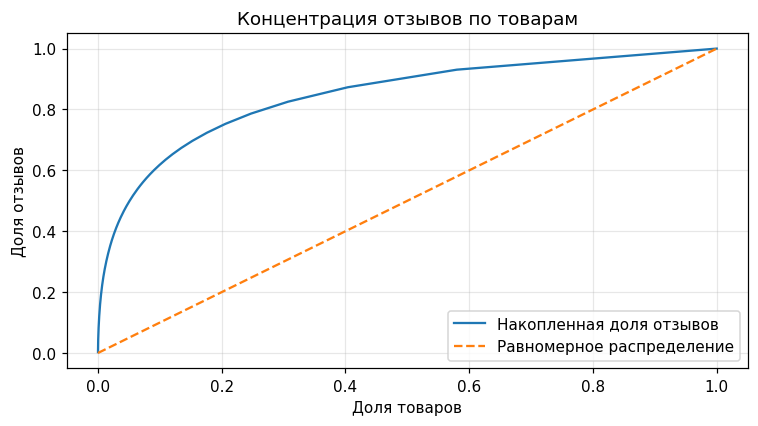

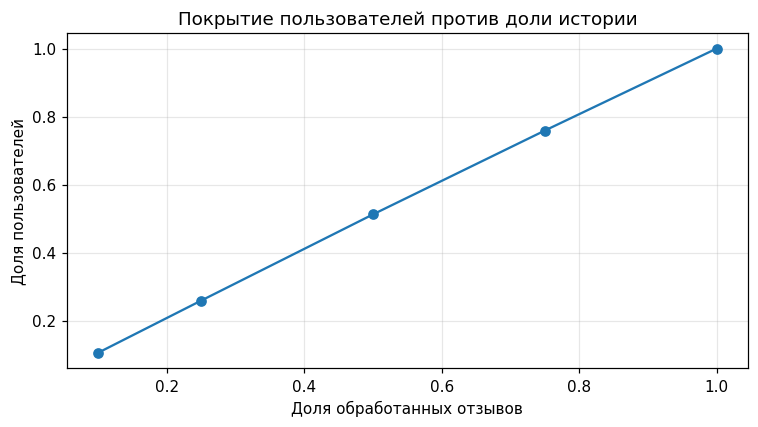

In [8]:
# Параметры сценария, их нет в файле отзывов
AOV_RUB = 1800          # принятый средний чек категории
MARGIN = 0.25           # принятая валовая маржа
UPLIFT = 0.15           # цель задания
DEV_COST_RUB = 350_000  # разовая разработка
COMPUTE_MONTH_RUB = 6_000  # небольшой сервис инференса и ночной пересчёт

year_end = df["dt"].max()
year_start = year_end - pd.Timedelta(days=365)
year_df = df[df["dt"].between(year_start, year_end)]
purchases = int(year_df["verified_purchase"].fillna(False).sum())
if purchases == 0:
    purchases = int(len(year_df))

gross_uplift = purchases * AOV_RUB * UPLIFT * MARGIN
infra_year = cost_year + COMPUTE_MONTH_RUB * 12
total_cost_year = infra_year + DEV_COST_RUB / 3  # разработку относим на 3 года
roi = (gross_uplift - total_cost_year) / total_cost_year if total_cost_year else float("nan")
payback_months = DEV_COST_RUB / (gross_uplift / 12) if gross_uplift else float("inf")

print(f"Подтверждённых покупок за последние 365 дней: {purchases}")
print(f"Оценка доп. маржи в год: {gross_uplift:,.0f} ₽")
print(f"Инфраструктура в год: {infra_year:,.0f} ₽")
print(f"ROI при разноске разработки на 3 года: {roi:.2f}")
print(f"Окупаемость разработки: {payback_months:.1f} мес.")

# ABC: насколько отзывы сконцентрированы на небольшой доле товаров
by_asin = df.groupby("asin").size().sort_values(ascending=False)
share_items = np.arange(1, len(by_asin) + 1) / len(by_asin)
share_reviews = by_asin.cumsum().to_numpy() / by_asin.sum()
top20 = float(by_asin.head(max(int(len(by_asin) * 0.2), 1)).sum() / by_asin.sum())
print(f"Доля отзывов у 20% самых обсуждаемых товаров: {top20:.1%}")
print(f"Уникальных товаров: {df['asin'].nunique()}, пользователей: {df['user_id'].nunique()}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(share_items, share_reviews, label="Накопленная доля отзывов")
ax.plot([0, 1], [0, 1], linestyle="--", label="Равномерное распределение")
ax.set_title("Концентрация отзывов по товарам")
ax.set_xlabel("Доля товаров")
ax.set_ylabel("Доля отзывов")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Грубая кривая ценности: больше истории — выше покрытие пользователей, но с насыщением
coverage = []
months_sorted = (
    df.dropna(subset=["dt"]).sort_values("dt")
)
cut_points = [0.1, 0.25, 0.5, 0.75, 1.0]
for part in cut_points:
    piece = months_sorted.head(int(len(months_sorted) * part))
    users = piece["user_id"].nunique()
    coverage.append(users / df["user_id"].nunique())
value_curve = pd.DataFrame({"Доля данных": cut_points, "Покрытие пользователей": coverage})
print(value_curve.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(value_curve["Доля данных"], value_curve["Покрытие пользователей"], marker="o")
ax.set_title("Покрытие пользователей против доли истории")
ax.set_xlabel("Доля обработанных отзывов")
ax.set_ylabel("Доля пользователей")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(
    "Вывод по ценности: хранение почти ничего не стоит по сравнению с разработкой. "
    f"При принятом чеке {AOV_RUB} ₽ и марже {MARGIN:.0%} цель +15% окупает разработку примерно за {payback_months:.1f} мес. "
    f"При этом {top20:.0%} отзывов сидят на 20% товаров: длинный хвост можно обновлять реже. "
    "Через год ценность не исчезнет, пока лента остаётся персональной, но модель нужно пересчитывать: ассортимент и вкусы смещаются."
)


## Часть 6. Выбор технологий

Объём категории маленький, задержка выдачи жёсткая, а текст и оценка одинаково нужны модели. Поэтому хранение и обучение отделяем от онлайн-ответа.


In [9]:
stack = pd.DataFrame({
    "Задача": [
        "Хранение сырых отзывов",
        "Ночной пересчёт признаков",
        "Онлайн-выдача",
        "Оркестрация",
        "Учёт моделей",
    ],
    "Выбор": [
        "Yandex Object Storage, Parquet + ледяной класс для истории старше 180 дней",
        "Pandas, пока Parquet меньше 8 ГБ; дальше Spark",
        "Уже посчитанные рекомендации в ключе пользователь-товар, ответ быстрее 100 мс",
        "Ежедневный граф задач (Prefect или Airflow)",
        "MLflow для метрик и версий модели",
    ],
    "Почему не соседний вариант": [
        "CSV дороже по месту, база сразу на всех отзывах плохо держит вложенный текст",
        "Flink для суточного пересчёта этой категории избыточен",
        "Часовой batch не укладывается в 100 мс",
        "Ручной запуск легко пропускает дубликаты и сбои",
        "Без реестра непонятно, какая модель сейчас в выдаче",
    ],
})
display(stack)

roadmap = pd.DataFrame({
    "Месяцы": ["1", "2", "3–4", "5", "6"],
    "Этап": [
        "Приём JSONL, проверка оценки и ключей, слой Parquet",
        "Витрина «пользователь-товар» и базовая модель по оценкам",
        "Текст отзыва как признак, офлайн-метрика качества ленты",
        "Онлайн-выдача и замер задержки",
        "Архив старых партиций и пересчёт ROI по факту среднего чека",
    ],
    "Метрика успеха": [
        "Доля битых оценок < 1%",
        "Покрытие пользователей с историей",
        "Рост качества против популярных товаров",
        "p95 инференса < 100 мс",
        "Есть или нет прирост среднего чека на тесте",
    ],
})
display(roadmap)

risks = pd.DataFrame({
    "Риск": [
        "Мало покупок у нового пользователя",
        "Смещение оценок из-за дублей",
        "Пустой текст",
        "Рост сразу нескольких категорий",
    ],
    "Что делаем": [
        "Холодный старт закрываем популярными товарами категории",
        "Идемпотентный ключ user_id + asin + timestamp",
        "Опираемся на оценку, текст используем только если он есть",
        "Тот же Parquet отдаём в Spark, код агрегации не переписываем с нуля",
    ],
})
display(risks)


Задача,Выбор,Почему не соседний вариант
Хранение сырых отзывов,"Yandex Object Storage, Parquet + ледяной класс для истории старше 180 дней","CSV дороже по месту, база сразу на всех отзывах плохо держит вложенный текст"
Ночной пересчёт признаков,"Pandas, пока Parquet меньше 8 ГБ; дальше Spark",Flink для суточного пересчёта этой категории избыточен
Онлайн-выдача,"Уже посчитанные рекомендации в ключе пользователь-товар, ответ быстрее 100 мс",Часовой batch не укладывается в 100 мс
Оркестрация,Ежедневный граф задач (Prefect или Airflow),Ручной запуск легко пропускает дубликаты и сбои
Учёт моделей,MLflow для метрик и версий модели,"Без реестра непонятно, какая модель сейчас в выдаче"


Месяцы,Этап,Метрика успеха
1,"Приём JSONL, проверка оценки и ключей, слой Parquet",Доля битых оценок < 1%
2,Витрина «пользователь-товар» и базовая модель по оценкам,Покрытие пользователей с историей
3–4,"Текст отзыва как признак, офлайн-метрика качества ленты",Рост качества против популярных товаров
5,Онлайн-выдача и замер задержки,p95 инференса < 100 мс
6,Архив старых партиций и пересчёт ROI по факту среднего чека,Есть или нет прирост среднего чека на тесте


Риск,Что делаем
Мало покупок у нового пользователя,Холодный старт закрываем популярными товарами категории
Смещение оценок из-за дублей,Идемпотентный ключ user_id + asin + timestamp
Пустой текст,"Опираемся на оценку, текст используем только если он есть"
Рост сразу нескольких категорий,"Тот же Parquet отдаём в Spark, код агрегации не переписываем с нуля"


### Схема обработки

```mermaid
flowchart LR
  source[JSONL_отзывы] --> check[Проверка_качества]
  check --> lake[ObjectStorage_Parquet]
  lake --> batch[Ночной_пересчёт]
  batch --> mart[Витрина_пользователь_товар]
  mart --> model[Модель_рекомендаций]
  model --> api[Выдача_до_100_мс]
  lake --> ice[Архив_старше_180_дней]
```


## Результаты


In [10]:
print("Итог по 5V")
print(f"Volume: несжатый JSONL {raw_mb:.1f} МБ, CSV {csv_mb:.1f} МБ, Parquet {parquet_mb:.1f} МБ, Avro {avro_mb:.1f} МБ.")
print(f"При текущем темпе 1 ТБ наберётся примерно за {months_to_tb:.0f} мес. Год хранения оценён в {cost_year:.0f} ₽.")
print(f"Velocity: в среднем {avg_rps:.4f} записей/с, пик {peak_rps:.3f} записей/с, CV по дням {cv:.2f}.")
print(f"Лимит сценария {limit_ms} мс. Часовой batch его не выполняет, поточечная обработка занимает около {per_row_ms:.4f} мс.")
print(f"Variety: текст даёт {text_share:.1%} несжатого объёма, изображения есть у {df['has_image'].mean():.2%} отзывов.")
if ge_success is None:
    ge_text = "пакет в этой сессии не импортировался"
elif ge_success:
    ge_text = "прошла"
else:
    ge_text = "не прошла"
print(f"Veracity: дубликатов по ключу {dup_count}, оценок в диапазоне 1–5 — {rating_ok:.2f}%. Проверка Great Expectations: {ge_text}.")
print(f"Value: доп. маржа около {gross_uplift:,.0f} ₽/год при параметрах AOV={AOV_RUB} ₽ и марже {MARGIN:.0%}. ROI={roi:.2f}, окупаемость {payback_months:.1f} мес.")
print()
print("Вывод")
print(
    "Работа выполнена на публичных отзывах Amazon Reviews 2023 категории All_Beauty, сценарий — рекомендательная система с целью +15% к среднему чеку и задержкой выдачи меньше 100 мс. "
    f"Сейчас это {len(df):,} отзывов и около {parquet_mb:.0f} МБ в Parquet, то есть объём ещё не большой: Pandas справляется, а переход к Spark заложен на пороге 8 ГБ. "
    f"Скорость поступления низкая в среднем ({avg_rps:.4f} записей/с), пик {peak_rps:.3f} записей/с, суточный поток неровный (CV={cv:.2f}). Обучение оставляем ночным batch, а выдачу — отдельным чтением уже готовых рекомендаций: разбор одной строки занимает около {per_row_ms:.4f} мс. "
    f"Главное разнообразие — текст ({text_share:.0%} байт) и редкие вложенные картинки. "
    f"Качество в целом рабочее: в диапазоне 1–5 находится {rating_ok:.2f}% оценок, дубликатов по пользователю, товару и времени — {dup_count}. Проверка Great Expectations: {ge_text}. "
    f"При принятых параметрах чека и маржи разработка окупается примерно за {payback_months:.1f} мес., а само хранение года данных стоит около {cost_year:.0f} ₽. "
    "Затраты на обработку этой категории оправданы: узкое место не диск, а качество модели и задержка ответа."
)


Итог по 5V
Volume: несжатый JSONL 311.5 МБ, CSV 185.1 МБ, Parquet 114.4 МБ, Avro 177.8 МБ.
При текущем темпе 1 ТБ наберётся примерно за 2548945 мес. Год хранения оценён в 1 ₽.
Velocity: в среднем 0.0010 записей/с, пик 0.040 записей/с, CV по дням 1.41.
Лимит сценария 100 мс. Часовой batch его не выполняет, поточечная обработка занимает около 0.0005 мс.
Variety: текст даёт 41.8% несжатого объёма, изображения есть у 8.51% отзывов.
Veracity: дубликатов по ключу 7276, оценок в диапазоне 1–5 — 100.00%. Проверка Great Expectations: прошла.
Value: доп. маржа около 1,738,800 ₽/год при параметрах AOV=1800 ₽ и марже 25%. ROI=8.22, окупаемость 2.4 мес.

Вывод
Работа выполнена на публичных отзывах Amazon Reviews 2023 категории All_Beauty, сценарий — рекомендательная система с целью +15% к среднему чеку и задержкой выдачи меньше 100 мс. Сейчас это 701,528 отзывов и около 114 МБ в Parquet, то есть объём ещё не большой: Pandas справляется, а переход к Spark заложен на пороге 8 ГБ. Скорость поступления